# LeetCode #25: Reverse Nodes in k-Group

https://leetcode.com/problems/reverse-nodes-in-k-group/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Recursion** | $O(n)$ | $O(n/k)$ |
| **Count + Iterative Reverse ★** | $O(n)$ | $O(1)$ |

`n` is the number of nodes and `k` the group size. $O(n)$ time means each node is touched a small,
fixed number of times: 5,000 nodes, a few tens of thousands of steps. $O(n/k)$ space is one stack
frame per group, so 5,000 nodes in groups of 2 is 2,500 nested calls. $O(1)$ means a handful of
pointers, whatever the size.

---

## Understanding the Methods

### Recursion
Check that `k` nodes are left, reverse them, and let a recursive call handle the rest of the list,
attaching its result after the reversed group. Clean to write, but every group adds a stack frame.

### Optimal: Count + Iterative Reverse ★
Walk the list one group at a time. Before touching a group, step `k` nodes ahead to make sure a full
group exists; if not, leave the remainder alone and stop. Otherwise reverse the group's arrows in
place and splice it back between the node before it and the node after it. A **dummy** node in front
of the head means the first group has a "node before it" too.

The neat trick: start the reversal with `prev` set to the node *after* the group. Then the group's
first node, which becomes its last, automatically ends up pointing at the rest of the list.

**Why this is better than recursion:** same linear time, but no stack frame per group.

**Constraints:**
* The number of nodes in the list is `n`
* `1 <= k <= n <= 5000`
* `0 <= Node.val <= 1000`
* Only the nodes may be rearranged; their values must not be changed

## Explain Like I'm a Newbie

### Primer: reversing a linked list in place

Each node only knows the node after it. To reverse, walk forward with two pointers: `prev` (what
the current node should point back to) and `curr` (the node being flipped). At each step, save
`curr.next` first, point `curr.next` at `prev`, then move both forward one node:

```
prev=null  curr=1:   1 -> null       2 -> 3
prev=1     curr=2:   2 -> 1 -> null  3
prev=2     curr=3:   3 -> 2 -> 1 -> null
```

Skip the save and you lose the rest of the list the moment you overwrite `curr.next`.

### What the question is actually asking

Cut the list into groups of `k` nodes, from the front, and reverse each full group. If the last
group has fewer than `k` nodes, leave it exactly as it is.

```
k = 2:   1 2 | 3 4 | 5      ->   2 1 | 4 3 | 5
k = 3:   1 2 3 | 4 5        ->   3 2 1 | 4 5        (4 5 is short, untouched)
```

You have to move the nodes themselves, not swap their values.

### The one idea you need: each group is a small reversal with two loose ends

Reversing a whole linked list is a standard move: walk it flipping each arrow backwards. Here you do
that to a slice in the middle of a list, which leaves two loose ends to tie up:

- the node **before** the group must now point at the group's old *last* node (its new first), and
- the group's old *first* node (its new last) must point at the node **after** the group.

```
before:  [prev group] -> 1 -> 2 -> [next group]
after:   [prev group] -> 2 -> 1 -> [next group]
```

The second loose end ties itself if you start the reversal with `prev` set to the node after the
group instead of null: the first node you flip points there, and that node ends up last.

### What that means in code

1. A **dummy** node before the head, and `group_prev` starting on it.
2. Step `k` nodes from `group_prev`. If you fall off the end, fewer than `k` remain: stop.
3. Reverse from `group_start` up to that `k`-th node, with `prev` starting at `next_group`.
4. `group_prev.next = kth` ties the first loose end. Then `group_prev = group_start`, because the
   old first node is now the last node of this group, sitting just before the next one.

### Mistakes people make the first time

1. **Asking for one node too many.** Since the code needs `kth.next`, it's tempting to stop when
   `kth.next` is null. Both LeetCode samples still pass, because neither list ends exactly on a group
   boundary. Then `[1,2,3,4]` with `k = 4` comes back unreversed.
2. **Reversing the short leftover group.** `[1,2,3,4,5]`, `k = 3` gives `3 2 1 5 4` instead of
   `3 2 1 4 5`.
3. **Advancing `group_prev` to `kth`.** After the reversal `kth` is the group's *first* node; the
   node before the next group is `group_start`.
4. **Swapping values instead of nodes.** It gives the right output, but the problem forbids it.

### Things worth knowing

Every node is visited twice, once by the step-ahead check and once by the reversal, so it's still
linear. `k = 1` reverses one-node groups, which changes nothing.

## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The 30-second pitch

> **You:** "One group at a time: check that k nodes exist, reverse them in place, and splice the group back between the node before it and the node after it. A dummy node gives the first group a 'before', and starting the reversal with prev pointing at the next group makes the tail reconnect itself. O(n) time, O(1) space. The two places it goes wrong are the check for a full group and where the 'before' pointer moves afterwards."

---

### I slide the problem across the table

`[1,2,3,4,5]`, `k = 2`, answer `[2,1,4,3,5]`.

> **You:** "So reverse each full block of k from the front, and a block shorter than k at the end stays as it is. And I'm moving nodes, not rewriting values."

Then the clarifier I want:

> **You:** "If the length is an exact multiple of k, does the last block get reversed too?"

**"Yes, every full block."** That's the question. It sounds obvious, but it's exactly the boundary both samples avoid, and the bug I'm watching for lives there.

> **You:** "Can I use recursion, or do you want constant space?"

**"Constant space, if you can."** That's the follow-up most people only get asked; you've just told me you know the recursive version costs a frame per group. "Can k be zero?" isn't worth asking: the constraints say at least 1.

---

### Now tell me what's actually hard about it

"I'll reverse each group" restates the problem. Reversing a list is easy. What's different here?

> **You:** "Reversing a whole list, I only care about the inside. Reversing a slice, there are two outside connections. The node before the group has to point at what used to be the group's last node, and what used to be the first node has to point at whatever comes after the group. And I have to know a group is full before I start flipping, because a short group must be left alone and I can't un-flip cheaply."

Then the plan falls out:

> **You:** "So for each group: look k ahead first. If there's a k-th node, remember the node after it, reverse the k nodes, then fix both outside connections. A dummy at the front so the first group has a node before it like every other group."

That's the understanding. The only "technique" is in-place reversal, which you already know; the problem is bookkeeping, and you've named the two pieces of it.

This is a problem where I'd like to see a drawing before any code: one group in a box, the node before it and the node after it outside, and two arrows marked "these change". It takes twenty seconds, and every line you write afterwards maps onto one of those arrows.

---

### Before you touch the board, tell me the shape and the cost

> **You:** "An outer loop over groups, with `group_prev` starting at the dummy. Inside: find `kth` by stepping k from `group_prev`; if it's null, break. Save `group_start` and `next_group`. Reverse with `prev = next_group`, stopping when `curr` reaches `next_group`. Then `group_prev.next = kth` and `group_prev = group_start`."

> **You:** "Each node is stepped over once by the look-ahead and once by the reversal, so about 2n steps, O(n). Five pointers, O(1)."

If you'd written it recursively I'd accept the logic and then ask about the stack. For 5,000 nodes in pairs that's 2,500 nested calls: survivable in most languages, but it's the space I asked you not to use, and it's the follow-up I'd have asked next anyway.

---

### Now whiteboard it

```
dummy = ListNode(0, head)
group_prev = dummy
while True:
    kth = get_kth(group_prev, k)
    if not kth:
        break
```

> **You:** "Stepping k from `group_prev` lands on the k-th node of this group. If I fall off, fewer than k are left, and they stay as they are."

This is where I listen hardest. Some people write `if not kth or not kth.next` because they're about to read `kth.next`. That passes both samples and leaves the last group of `[1,2,3,4]`, `k = 4`, unreversed. `kth.next` being null is fine: it just means the group runs to the end.

```
    group_start = group_prev.next
    next_group = kth.next
    prev, curr = next_group, group_start
    while curr != next_group:
        tmp = curr.next
        curr.next = prev
        prev = curr
        curr = tmp
```

> **You:** "Starting `prev` at `next_group` instead of null means the first node I flip, `group_start`, points straight at the next group. That's the second loose end tied for free."

If you start `prev` at null, it still works, but you need an extra `group_start.next = next_group` afterwards. Either is fine; I just want you to know which one you're relying on.

I also like the loop condition. Stopping when `curr` reaches `next_group`, rather than counting k flips, means the reversal can't overrun: its boundary is a node you've already found, not a number you have to keep in sync with the look-ahead.

```
    group_prev.next = kth
    group_prev = group_start
return dummy.next
```

> **You:** "`kth` is now the group's first node, so the node before the group points at it. And `group_start` is now the group's *last* node, so it's the 'before' for the next group. Moving `group_prev` to `kth` instead is the classic slip."

---

### Walk me through it before you say you're done

> **You:** "`[1,2,3,4,5]`, `k = 2`. From the dummy, two steps reaches 2: a full group. Start is 1, next group is 3. Flip 1 to point at 3, flip 2 to point at 1. Dummy points at 2, `group_prev` moves to 1. From 1, two steps reaches 4: start 3, next 5, flip, 1 points at 4, `group_prev` is 3. From 3, two steps falls off after 5, so stop. `2 1 4 3 5`."

> **You:** "And the boundary you said counts: `[1,2,3,4]`, `k = 4`. Four steps from the dummy reaches 4, whose next is null. That's a full group, so I reverse it; `next_group` is null, so the old head ends up pointing at null. `4 3 2 1`."

> **You:** "One more: `k = 1`. Every group is a single node, the reversal flips one arrow to point where it already pointed, and the list comes back unchanged. Not interesting, but it confirms nothing special-cases k."

---

### Then tell me what it leans on, before I ask

It's optimal: linear time, constant space. So the useful thing to volunteer is how it generalises:

> **You:** "If you wanted the short leftover group reversed too, that's one change: don't break when `kth` is null, reverse whatever's left. And if the groups were counted from the end instead of the front, I'd take the length first, skip `n mod k` nodes, and then run exactly this loop. The look-ahead is the only part that knows where groups start."

That's the conversation I want at the end: you showing me which line owns which decision.

---

### What would worry me

Copying the values into an array, reversing chunks and writing them back; it gets the right output and breaks the stated rule. A check that demands `kth.next`. Moving `group_prev` to `kth`. And anyone who can't say, before writing the loop, which two connections have to change when a slice is reversed.

## Solutions

The C#, Python and Go versions all walk the list one group at a time: look `k` ahead, reverse the group in place, and splice it back. The comments mark the full-group check, the `prev = nextGroup` trick and where `groupPrev` moves. The Rust version takes a different route; see its note.

### C#

In [ ]:
public class ListNode {
    public int val;
    public ListNode next;
    public ListNode(int val=0, ListNode next=null) { this.val = val; this.next = next; }
}

public class Solution {
    public ListNode ReverseKGroup(ListNode head, int k) {
        // The dummy gives the first group a "node before it", like every other group
        var dummy = new ListNode(0, head);
        var groupPrev = dummy;
        while (true) {
            // Step k from the node before the group: lands on the group's k-th node.
            // Null means fewer than k remain, and they stay as they are. (kth.next being
            // null is fine: that just means this full group runs to the end of the list.)
            var kth = GetKth(groupPrev, k);
            if (kth == null) break;
            var groupStart = groupPrev.next;
            var nextGroup  = kth.next;
            // Reverse [groupStart..kth]. prev starts at nextGroup, not null, so the first
            // node flipped (groupStart, the group's new tail) already points at the next group.
            ListNode prev = nextGroup, curr = groupStart;
            while (curr != nextGroup) {
                var tmp = curr.next;   // save before overwriting
                curr.next = prev;
                prev = curr;
                curr = tmp;
            }
            groupPrev.next = kth;    // kth is the new head of the reversed group
            groupPrev = groupStart;  // groupStart is its new TAIL: the node before the next group
        }
        return dummy.next;
    }

    // Walks k steps from curr; returns null if the list runs out first
    private ListNode GetKth(ListNode curr, int k) {
        while (curr != null && k > 0) { curr = curr.next; k--; }
        return curr;
    }
}

### Python

`get_kth` is a nested function: it's only used here, so it lives inside the method.

In [ ]:
from typing import Optional

class ListNode:
    def __init__(self, val=0, next=None):
        self.val = val
        self.next = next

class Solution:
    def reverseKGroup(self, head: Optional[ListNode], k: int) -> Optional[ListNode]:
        # Walks k steps from node; returns None if the list runs out first
        def get_kth(node, k):
            while node and k > 0:
                node = node.next
                k -= 1
            return node

        # The dummy gives the first group a "node before it", like every other group
        dummy = ListNode(0, head)
        group_prev = dummy
        while True:
            # Step k from the node before the group: lands on the group's k-th node.
            # None means fewer than k remain, and they stay as they are. (kth.next being
            # None is fine: that just means this full group runs to the end of the list.)
            kth = get_kth(group_prev, k)
            if not kth:
                break
            group_start = group_prev.next
            next_group = kth.next
            # Reverse [group_start..kth]. prev starts at next_group, not None, so the first
            # node flipped (group_start, the group's new tail) already points at the next group.
            prev, curr = next_group, group_start
            while curr != next_group:
                tmp = curr.next   # save before overwriting
                curr.next = prev
                prev = curr
                curr = tmp
            group_prev.next = kth       # kth is the new head of the reversed group
            group_prev = group_start    # group_start is its new TAIL: the node before the next group
        return dummy.next

### Go

`getKth` is a function value assigned to a local variable. It doesn't call itself, so unlike a recursive closure it doesn't need a separate `var` declaration first.

In [ ]:
package main

type ListNode struct {
    Val  int
    Next *ListNode
}

func reverseKGroup(head *ListNode, k int) *ListNode {
    // Walks k steps from node; returns nil if the list runs out first
    getKth := func(node *ListNode, k int) *ListNode {
        for node != nil && k > 0 {
            node = node.Next
            k--
        }
        return node
    }

    // The dummy gives the first group a "node before it", like every other group
    dummy := &ListNode{Next: head}
    groupPrev := dummy
    for {
        // Step k from the node before the group: lands on the group's k-th node.
        // nil means fewer than k remain, and they stay as they are. (kth.Next being
        // nil is fine: that just means this full group runs to the end of the list.)
        kth := getKth(groupPrev, k)
        if kth == nil {
            break
        }
        groupStart := groupPrev.Next
        nextGroup := kth.Next
        // Reverse [groupStart..kth]. prev starts at nextGroup, not nil, so the first
        // node flipped (groupStart, the group's new tail) already points at the next group.
        prev, curr := nextGroup, groupStart
        for curr != nextGroup {
            tmp := curr.Next // save before overwriting
            curr.Next = prev
            prev = curr
            curr = tmp
        }
        groupPrev.Next = kth    // kth is the new head of the reversed group
        groupPrev = groupStart  // groupStart is its new TAIL: the node before the next group
    }
    return dummy.Next
}

### Rust

This version doesn't relink nodes: it copies the values into a `Vec`, reverses each full chunk with `vals[i..i+k].reverse()`, and builds a new list. The output is right, but it uses $O(n)$ extra memory instead of $O(1)$, and it gets there by rearranging values, which the problem's rules forbid. An in-place Rust version is possible: take each group out of the list with `Option::take`, reverse it, and walk a single `&mut` cursor to its new tail.

In [ ]:
#[derive(PartialEq, Eq, Clone, Debug)]
pub struct ListNode {
    pub val: i32,
    pub next: Option<Box<ListNode>>,
}

pub struct Solution;

impl Solution {
    pub fn reverse_k_group(head: Option<Box<ListNode>>, k: i32) -> Option<Box<ListNode>> {
        // Copies the values into a Vec instead of relinking nodes (see the note above:
        // O(n) extra memory, and it rearranges values rather than nodes)
        let mut vals = Vec::new();
        let mut cur = &head;
        while let Some(node) = cur {
            vals.push(node.val);
            cur = &node.next;
        }
        // Reverse each FULL chunk of k; a shorter tail chunk is left as it is
        let n = vals.len();
        let k = k as usize;
        let mut i = 0;
        while i + k <= n {
            vals[i..i+k].reverse();
            i += k;
        }
        // Rebuild back to front: each new node points at the list built so far
        let mut head: Option<Box<ListNode>> = None;
        for &v in vals.iter().rev() {
            head = Some(Box::new(ListNode { val: v, next: head }));
        }
        head
    }
}

## Example Scenarios

### 1. Common Case — Pairs With a Leftover
**Input:** `head = [1,2,3,4,5]`, `k = 2`

Two full pairs, $(1,2)$ and $(3,4)$, are reversed in place and spliced back. Stepping two nodes ahead
from 3 falls off the end after 5, so the lone 5 stays put. **Output:** `[2,1,4,3,5]`

### 2. Slightly Complex — Short Leftover Group
**Input:** `head = [1,2,3,4,5]`, `k = 3`

One full group becomes $3 \to 2 \to 1$, and its old head, 1, ends up pointing at 4 because the
reversal started with `prev` on 4. Only two nodes are left after that, so $4 \to 5$ is untouched.
**Output:** `[3,2,1,4,5]`

### 3. Edge Case: Time Factor — One Group, Whole List
**Input:** `head = [1,2,3,4]`, `k = 4`

Every node is visited about twice whatever `k` is, so time doesn't really depend on the grouping;
this input is here because the list ends exactly on a group boundary. `kth` is the last node and
`kth.next` is null, which still counts as a full group. **Output:** `[4,3,2,1]`

### 4. Edge Case: Space Factor — k = 1
**Input:** `head = [1,2,3]`, `k = 1`

The iterative version uses a few pointers for any input, so no input is worse for memory here.
Groups of one node reverse into themselves: the list comes back unchanged, after the loop has
still visited every node. **Output:** `[1,2,3]`

### 5. Almost-Impossible but Plausible — Several Groups Plus a Remainder
**Input:** `head = [1,2,3,4,5,6,7]`, `k = 3`

Two full groups, $(3,2,1)$ and $(6,5,4)$, with the second spliced after the first's new tail, 1.
The final 7 can't make a group of three, so it stays at the end. **Output:** `[3,2,1,6,5,4,7]`

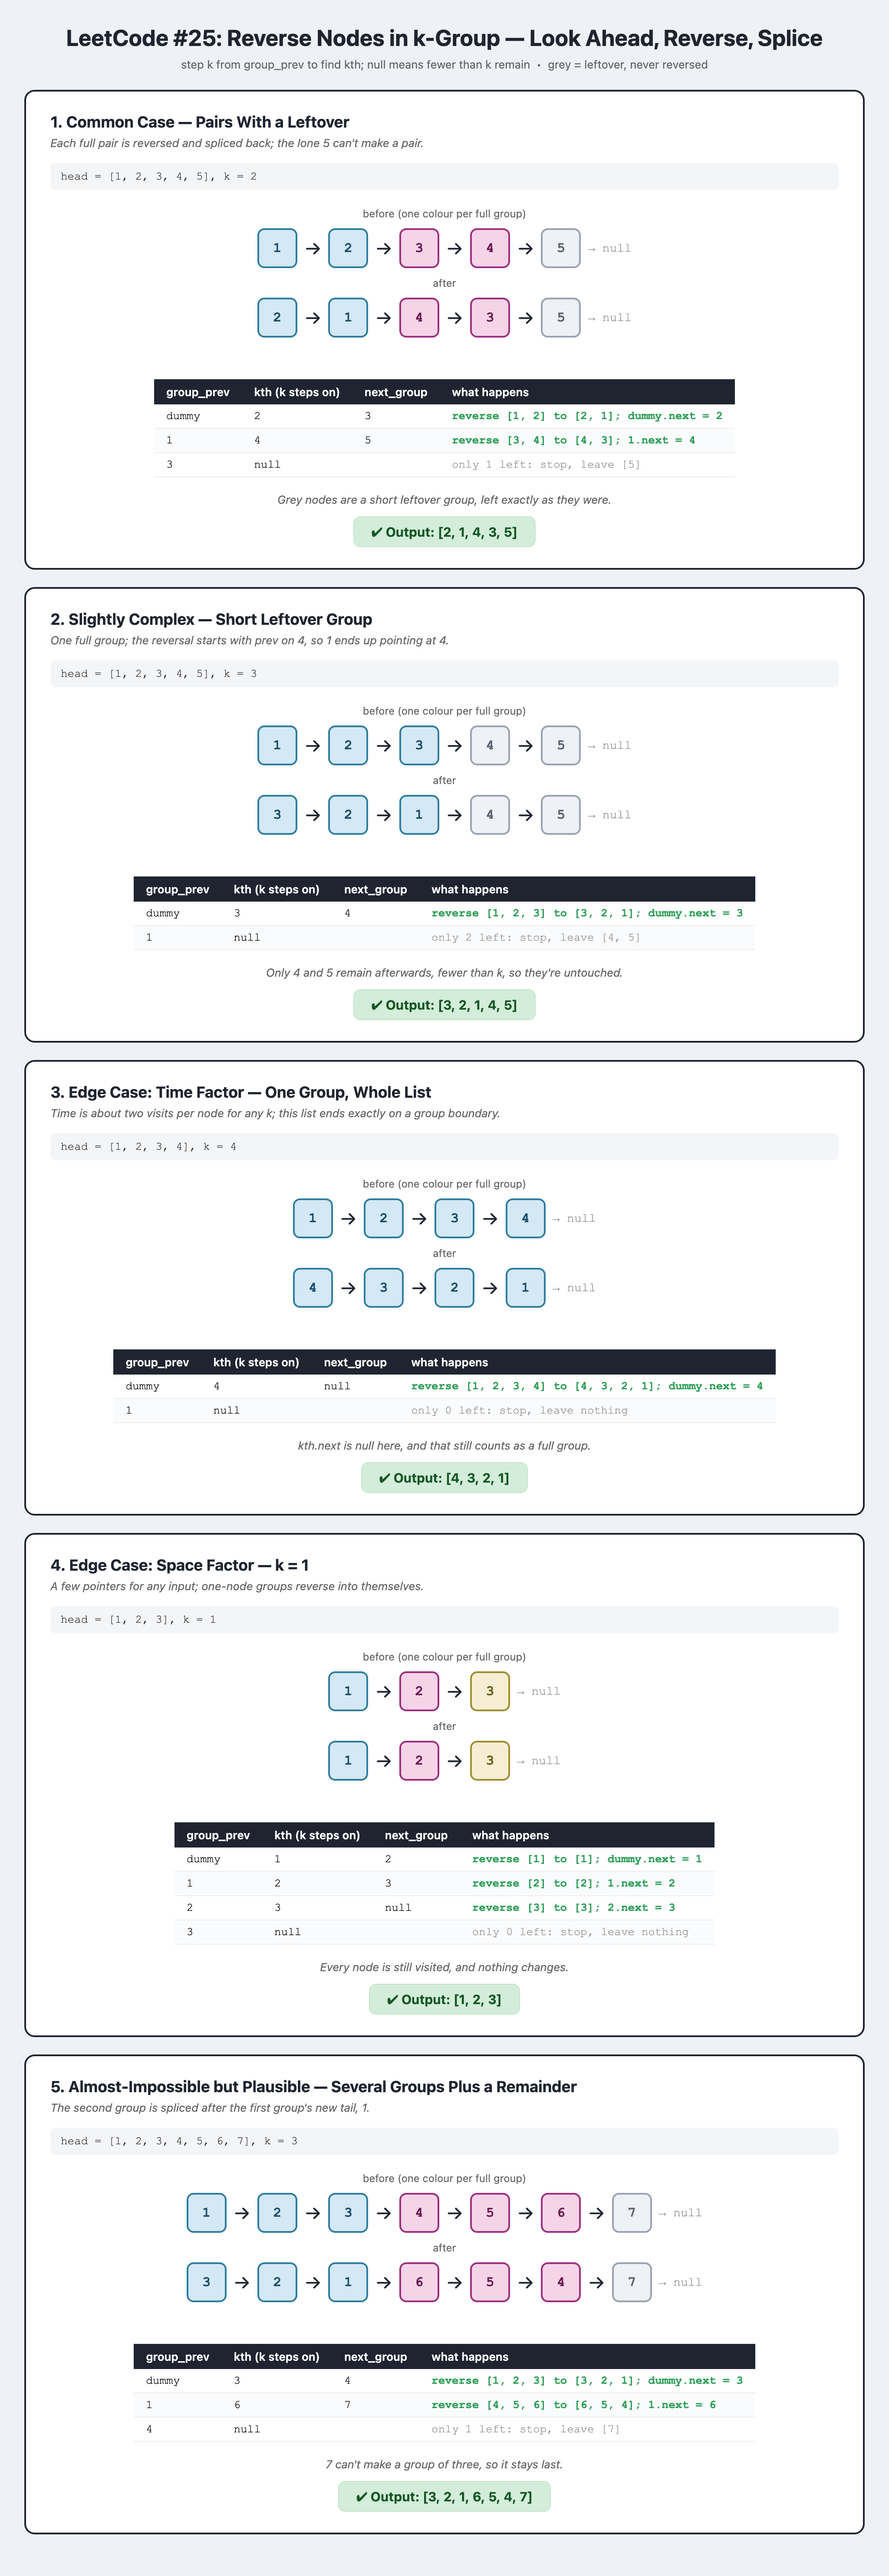

## Watch It Run

*Watch the first flip: because prev starts on the node after the group, the group's new tail is reconnected before the reversal even finishes.*

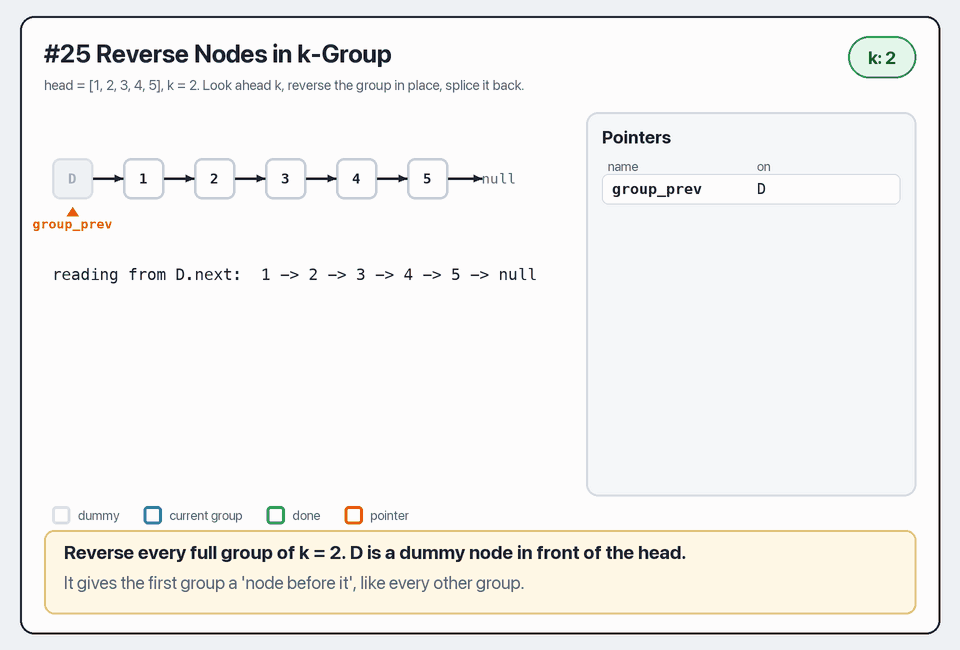